# Astrovascular Response Dynamics — Supplementary Computational Analysis

**Companion to:** *Astrovascular Response Dynamics and Cognitive Reliability in Early Alzheimer's Disease*, Sections 6.3–6.4.

This notebook is a reproducible **in silico feasibility demonstration**, not a fit to Alzheimer's disease data. It implements the effective neural and vascular state-space models, four mechanistic perturbations, an independently calibrated neural-to-vascular FIR predictor, the signed residual-maintenance contrast **M**, and the complementary relative-shape contrast **S**. It tests sensitivity to timing, drift, neural-observation error, and signal amplitude.

**Use:** Put this notebook in the project folder. Choose **Kernel → Restart Kernel and Run All Cells**. It writes publication-ready figure files into `figures/` and numerical summaries into `results/` relative to the notebook. No datasets, internet access, or proprietary packages are required.

**Interpretation:** The simulated astrocyte-sensitive delayed path is phenomenological; its cellular identity and effects on tissue oxygenation or subsequent cognition are *not* established by these simulations. Default time constants, gains, and impairment strengths are illustrative, rather than patient-specific measurements.

## 1. Reproducible numerical configuration and stimulus protocols

Four protocols: 5-s brief, 30-s sustained, and three 5-s pulses separated by 5-s or 20-s gaps. All begin after a 10-s prestimulus baseline and include 60 s of recovery. The simulator uses 0.1-s steps, while the observation model samples every 0.5 s.

In [1]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# Numerical configuration
DT = 0.1
BASELINE_S = 10.0
RECOVERY_S = 60.0
SEED = 20261015

def repeated_windows(isi_s, n=3, on_s=5.0):
    return [
        (
            BASELINE_S + k * (on_s + isi_s),
            BASELINE_S + k * (on_s + isi_s) + on_s
        )
        for k in range(n)
    ]

protocols = {
    "Brief (5 s)": [
        (BASELINE_S, BASELINE_S + 5.0)
    ],
    "Sustained (30 s)": [
        (BASELINE_S, BASELINE_S + 30.0)
    ],
    "Repeated (ISI 5 s)": repeated_windows(5.0),
    "Repeated (ISI 20 s)": repeated_windows(20.0)
}

def make_stimulus(windows):
    assert windows
    assert all(stop > start >= 0 for start, stop in windows)

    total_s = max(stop for _, stop in windows) + RECOVERY_S
    n_samples = round(total_s / DT)
    assert np.isclose(n_samples * DT, total_s)

    t = np.arange(n_samples) * DT
    u = np.zeros(n_samples, dtype=float)

    for start, stop in windows:
        a = round(start / DT)
        b = round(stop / DT)

        assert np.isclose(a * DT, start)
        assert np.isclose(b * DT, stop)
        assert not np.any(u[a:b]), "Overlapping stimuli"

        u[a:b] = 1.0

    expected = sum(stop - start for start, stop in windows)

    assert np.isclose(DT * u.sum(), expected)
    assert np.all(u[:round(BASELINE_S / DT)] == 0)
    assert np.all(
        u[round(max(e for _, e in windows) / DT):] == 0
    )
    assert set(np.unique(u)).issubset({0.0, 1.0})

    starts = np.flatnonzero(
        np.diff(np.r_[0.0, u]) == 1.0
    )
    stops = np.flatnonzero(
        np.diff(np.r_[u, 0.0]) == -1.0
    ) + 1

    assert len(starts) == len(stops) == len(windows)
    assert np.allclose(
        (stops - starts) * DT,
        [e - s for s, e in windows]
    )

    return t, u

from dataclasses import dataclass, replace
from scipy.integrate import solve_ivp
from scipy.optimize import nnls
from numpy.lib.stride_tricks import sliding_window_view
from pathlib import Path
import pandas as pd
import json

OUTPUT = Path.cwd()
(OUTPUT / "figures").mkdir(exist_ok=True)
(OUTPUT / "results").mkdir(exist_ok=True)
print("Project directory:", OUTPUT)
print("Protocols:", ", ".join(protocols))


Project directory: /mnt/data/Astrovascular_GitHub_Ready
Protocols: Brief (5 s), Sustained (30 s), Repeated (ISI 5 s), Repeated (ISI 20 s)


## 2. Neural and vascular generators

The neural generator has a signed adaptation/facilitation variable and uses an exact piecewise-constant state update. The vascular model comprises a fast path, a two-stage delayed path, and an aggregate latent response. Both generators describe *normalized evoked responses*, not recorded EEG or physical oxygen concentration.

In [2]:
# STEP 2C — Audited neural-state generator
# Piecewise-exact integration; independent numerical verification

from dataclasses import dataclass
from scipy.integrate import solve_ivp
import numpy as np
import matplotlib.pyplot as plt


@dataclass(frozen=True)
class NeuralParameters:
    tau_n_s: float = 0.5
    tau_on_s: float = 10.0
    tau_off_s: float = 15.0
    q_ss: float = 0.0

    def __post_init__(self):
        taus = (self.tau_n_s, self.tau_on_s, self.tau_off_s)

        if not all(np.isfinite(v) and v > 0 for v in taus):
            raise ValueError("Time constants must be positive.")

        if not np.isfinite(self.q_ss) or not -0.9 <= self.q_ss <= 0.9:
            raise ValueError("q_ss outside the model domain.")


def exprel(z):
    """Stable evaluation of (exp(z)-1)/z."""
    if abs(z) < 1e-5:
        return 1 + z/2 + z*z/6 + z**3/24 + z**4/120
    return np.expm1(z) / z


def neural_generator(t, u, p):
    """
    Exact state update for piecewise-constant binary input.

    N: normalized evoked neural activity
    q: signed activity-dependent modulation
    """
    t = np.asarray(t, dtype=float)
    u = np.asarray(u, dtype=float)

    if t.ndim != 1 or u.ndim != 1 or len(t) != len(u):
        raise ValueError("Time and input dimensions do not match.")

    if len(t) < 2 or not np.all(np.diff(t) > 0):
        raise ValueError("Time must be strictly increasing.")

    if not np.all(np.isfinite(t)) or not np.all(np.isfinite(u)):
        raise ValueError("Nonfinite input detected.")

    if not np.all(np.isin(u, [0.0, 1.0])):
        raise ValueError("Only binary stimulation is supported.")

    N = np.zeros(len(t))
    q = np.zeros(len(t))

    for k, h in enumerate(np.diff(t)):
        tau_q = p.tau_on_s if u[k] else p.tau_off_s
        q_eq = u[k] * p.q_ss

        e_n = np.exp(-h / p.tau_n_s)
        e_q = np.exp(-h / tau_q)

        z = h * (1/p.tau_n_s - 1/tau_q)
        kernel = (h/p.tau_n_s) * e_n * exprel(z)

        q[k+1] = q_eq + (q[k] - q_eq) * e_q

        N[k+1] = (
            N[k] * e_n
            + u[k] * (1 + q_eq) * (-np.expm1(-h/p.tau_n_s))
            + u[k] * (q[k] - q_eq) * kernel
        )

    if not np.all(np.isfinite(N)) or not np.all(np.isfinite(q)):
        raise ArithmeticError("Nonfinite simulated states.")

    if N.min() < -1e-10 or N.max() > 1.9 + 1e-10:
        raise ArithmeticError("Neural state outside model bounds.")

    return N, q

# STEP 3A — Reference neurovascular dynamics
# Latent vascular response; no observation noise or disease effect

from dataclasses import dataclass
from scipy.integrate import solve_ivp
import numpy as np
import matplotlib.pyplot as plt


@dataclass(frozen=True)
class VascularParameters:
    tau_fast_s: float = 1.5
    tau_recruit_s: float = 6.0
    tau_delayed_s: float = 3.0
    tau_vascular_s: float = 1.0
    gain_fast: float = 0.75
    gain_delayed: float = 0.25

    def __post_init__(self):
        taus = (
            self.tau_fast_s,
            self.tau_recruit_s,
            self.tau_delayed_s,
            self.tau_vascular_s
        )
        gains = (self.gain_fast, self.gain_delayed)

        if not all(np.isfinite(x) and x > 0 for x in taus):
            raise ValueError("Invalid time constants")

        if not all(np.isfinite(x) and x >= 0 for x in gains):
            raise ValueError("Invalid pathway gains")


def simulate_vascular(t, neural, p):

    t = np.asarray(t, dtype=float)
    neural = np.asarray(neural, dtype=float)

    if (
        t.ndim != 1
        or neural.shape != t.shape
        or len(t) < 2
        or not np.all(np.diff(t) > 0)
    ):
        raise ValueError("Invalid time or neural input")

    if not (
        np.all(np.isfinite(t))
        and np.all(np.isfinite(neural))
    ):
        raise ValueError("Nonfinite input detected")

    def rhs(time, state):
        fast, recruitment, delayed, vascular = state

        n = np.interp(time, t, neural)

        return [
            (n - fast) / p.tau_fast_s,

            (n - recruitment) / p.tau_recruit_s,

            (recruitment - delayed) / p.tau_delayed_s,

            (
                p.gain_fast * fast
                + p.gain_delayed * delayed
                - vascular
            ) / p.tau_vascular_s
        ]

    solution = solve_ivp(
        rhs,
        (t[0], t[-1]),
        y0=[0.0, 0.0, 0.0, 0.0],
        t_eval=t,
        method="DOP853",
        max_step=np.min(np.diff(t)) / 2,
        rtol=1e-8,
        atol=1e-10
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    if not np.all(np.isfinite(solution.y)):
        raise ArithmeticError("Nonfinite vascular state")

    return solution.y


## 3. Numerical cross-check

The piecewise-exact neural solution is compared against an independent high-precision ODE integrator for all four protocols and three parameter settings. This verifies **numerics**, not biological validity. Development-only parameter fitting and profiling remain in the separate archival notebook.

In [3]:
# STEP 2D — Full-protocol independent verification

def independent_reference(t, windows, p):

    boundaries = sorted(set(
        [float(t[0]), float(t[-1])]
        + [v for pair in windows for v in pair]
    ))

    states = np.empty((2, len(t)))
    initial = np.zeros(2)

    for left, right in zip(boundaries[:-1], boundaries[1:]):

        midpoint = (left + right) / 2
        active = float(any(
            start <= midpoint < stop
            for start, stop in windows
        ))

        tau_q = p.tau_on_s if active else p.tau_off_s

        def rhs(time, state):
            neural, modulation = state

            return [
                (active * (1 + modulation) - neural)
                / p.tau_n_s,

                (active * p.q_ss - modulation)
                / tau_q
            ]

        solution = solve_ivp(
            rhs,
            (left, right),
            initial,
            method="DOP853",
            rtol=1e-11,
            atol=1e-12,
            max_step=p.tau_n_s / 2,
            dense_output=True
        )

        if not solution.success:
            raise RuntimeError(solution.message)

        mask = (t >= left) & (t < right)

        if np.any(mask):
            states[:, mask] = solution.sol(t[mask])

        initial = solution.y[:, -1]

    states[:, -1] = initial

    return states


parameter_sets = [
    NeuralParameters(0.5, 10.0, 15.0, -0.4),
    NeuralParameters(0.25, 3.0, 30.0, 0.4),
    NeuralParameters(1.0, 20.0, 5.0, 0.0)
]

all_errors = []

for name, windows in protocols.items():

    t_test, u_test = make_stimulus(windows)
    errors = []

    for p in parameter_sets:

        N, q = neural_generator(t_test, u_test, p)

        reference = independent_reference(
            t_test, windows, p
        )

        error = np.max(np.abs(
            np.vstack((N, q)) - reference
        ))

        errors.append(error)
        all_errors.append(error)

    print(
        f"{name:24s} "
        f"maximum error = {max(errors):.3e}"
    )

overall_error = max(all_errors)

print("\nOverall maximum error:", f"{overall_error:.3e}")
print("Independent comparisons:", len(all_errors))

assert np.isfinite(overall_error)
assert overall_error < 2e-9

print("\nFULL-PROTOCOL VERIFICATION PASSED")


Brief (5 s)              maximum error = 9.730e-12


Sustained (30 s)         maximum error = 9.730e-12


Repeated (ISI 5 s)       maximum error = 1.106e-11


Repeated (ISI 20 s)      maximum error = 1.162e-11

Overall maximum error: 1.162e-11
Independent comparisons: 12

FULL-PROTOCOL VERIFICATION PASSED


## 4. Reference and four competing mechanisms

The same binary stimulus is used for the reference and four predefined alternatives: (i) fast pathway gain reduction, (ii) delayed pathway gain reduction, (iii) neural adaptation, and (iv) uniform gain reduction. Gain perturbations are fixed at 50% for illustration; no conditional logic rewards a particular response pattern. The resulting curves are *latent vascular output*.

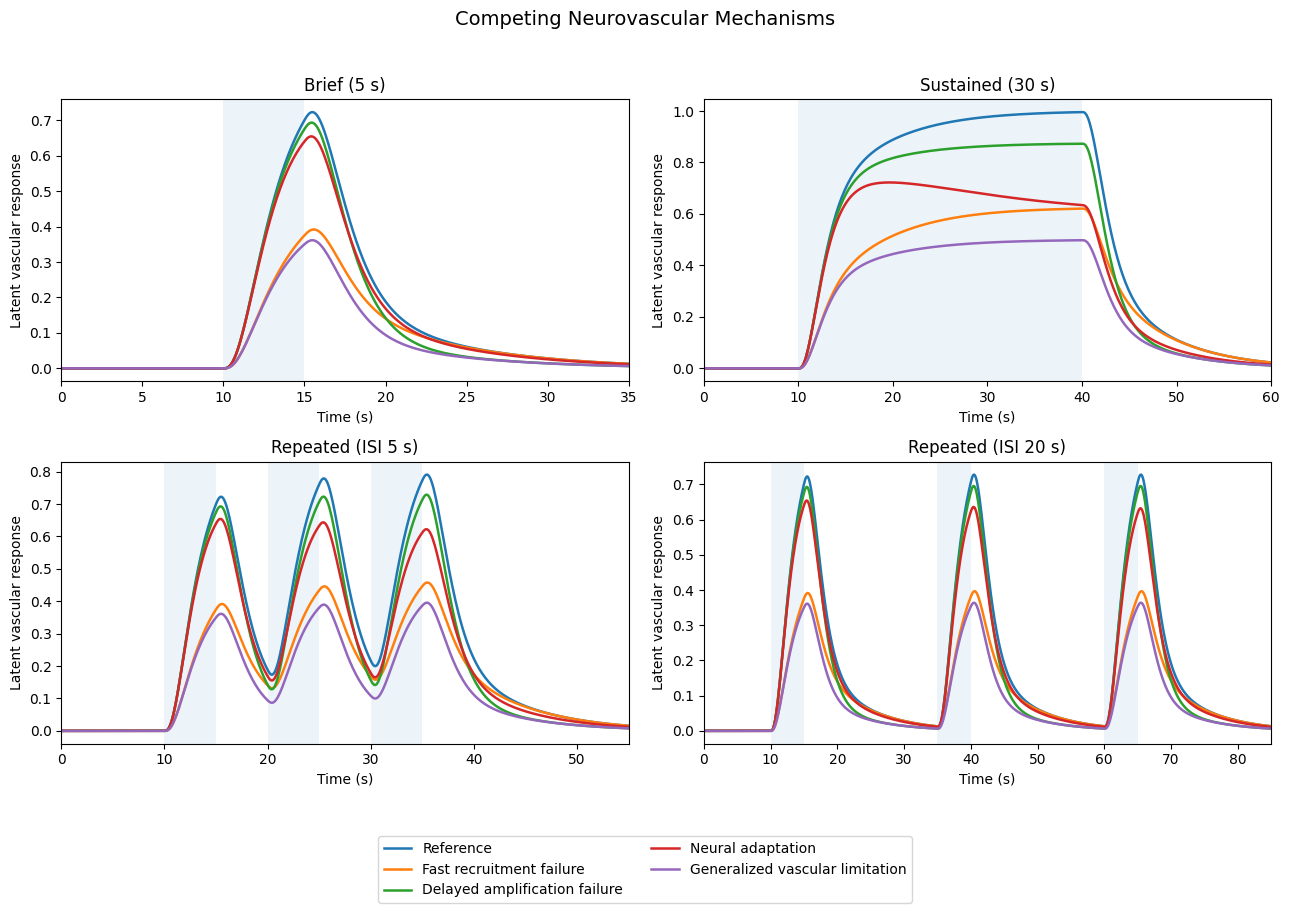


SUSTAINED-STIMULUS RESPONSE SUMMARY

Reference
  Neural early mean:   0.99999
  Neural late mean:    1.00000
  Vascular early mean: 0.81552
  Vascular late mean:  0.99311
  Vascular peak:       0.99561

Fast recruitment failure
  Neural early mean:   0.99999
  Neural late mean:    1.00000
  Vascular early mean: 0.45643
  Vascular late mean:  0.61811
  Vascular peak:       0.62061

Delayed amplification failure
  Neural early mean:   0.99999
  Neural late mean:    1.00000
  Vascular early mean: 0.76685
  Vascular late mean:  0.87155
  Vascular peak:       0.87280

Neural adaptation
  Neural early mean:   0.80197
  Neural late mean:    0.62733
  Vascular early mean: 0.70199
  Vascular late mean:  0.64287
  Vascular peak:       0.72222

Generalized vascular limitation
  Neural early mean:   0.99999
  Neural late mean:    1.00000
  Vascular early mean: 0.40776
  Vascular late mean:  0.49655
  Vascular peak:       0.49780

COMPETING MECHANISM SIMULATION COMPLETED


In [4]:
# STEP 3B — Competing mechanistic response dynamics
# Aligned with manuscript Sections 6.2 and 6.4

from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt

BASE_N = NeuralParameters(q_ss=0.0)
BASE_V = VascularParameters()

# Illustrative perturbations; not calibrated AD estimates
GAIN_REDUCTION = 0.50

SCENARIOS = {
    "Reference": (
        BASE_N,
        BASE_V
    ),

    "Fast recruitment failure": (
        BASE_N,
        replace(
            BASE_V,
            gain_fast=BASE_V.gain_fast * (1-GAIN_REDUCTION)
        )
    ),

    "Delayed amplification failure": (
        BASE_N,
        replace(
            BASE_V,
            gain_delayed=BASE_V.gain_delayed * (1-GAIN_REDUCTION)
        )
    ),

    "Neural adaptation": (
        replace(BASE_N, q_ss=-0.4),
        BASE_V
    ),

    "Generalized vascular limitation": (
        BASE_N,
        replace(
            BASE_V,
            gain_fast=BASE_V.gain_fast * (1-GAIN_REDUCTION),
            gain_delayed=BASE_V.gain_delayed * (1-GAIN_REDUCTION)
        )
    )
}

simulations = {}

for protocol_name, windows in protocols.items():

    t, u = make_stimulus(windows)

    simulations[protocol_name] = {
        "t": t,
        "u": u,
        "cases": {}
    }

    for scenario_name, (p_n, p_v) in SCENARIOS.items():

        neural, _ = neural_generator(t, u, p_n)

        states = simulate_vascular(t, neural, p_v)
        vascular = states[3]

        assert np.all(np.isfinite(vascular))
        assert np.all(np.isfinite(neural))

        simulations[protocol_name]["cases"][scenario_name] = {
            "neural": neural,
            "vascular": vascular
        }

    # Verify matched neural input for vascular-only changes
    cases = simulations[protocol_name]["cases"]
    n_reference = cases["Reference"]["neural"]

    for scenario_name in (
        "Fast recruitment failure",
        "Delayed amplification failure",
        "Generalized vascular limitation"
    ):
        np.testing.assert_allclose(
            cases[scenario_name]["neural"],
            n_reference,
            rtol=0,
            atol=1e-12
        )


fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (protocol_name, data) in zip(
    axes.flat, simulations.items()
):

    t = data["t"]

    for scenario_name, result in data["cases"].items():
        ax.plot(
            t,
            result["vascular"],
            linewidth=1.8,
            label=scenario_name
        )

    for start, stop in protocols[protocol_name]:
        ax.axvspan(start, stop, alpha=0.08)

    last_offset = max(
        stop for _, stop in protocols[protocol_name]
    )

    ax.set_xlim(0, last_offset + 20)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Latent vascular response")
    ax.set_title(protocol_name)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="lower center",
    ncol=2,
    bbox_to_anchor=(0.5, -0.02)
)

fig.suptitle(
    "Competing Neurovascular Mechanisms",
    fontsize=14
)

plt.tight_layout(rect=[0, 0.10, 1, 0.96])
plt.show()


# Prespecified descriptive readouts
data = simulations["Sustained (30 s)"]
t = data["t"]

early = (t >= 15) & (t < 20)
late = (t >= 35) & (t < 40)

print("\nSUSTAINED-STIMULUS RESPONSE SUMMARY")
print("=" * 75)

for name, result in data["cases"].items():

    n = result["neural"]
    v = result["vascular"]

    print(f"\n{name}")
    print(f"  Neural early mean:   {n[early].mean():.5f}")
    print(f"  Neural late mean:    {n[late].mean():.5f}")
    print(f"  Vascular early mean: {v[early].mean():.5f}")
    print(f"  Vascular late mean:  {v[late].mean():.5f}")
    print(f"  Vascular peak:       {v.max():.5f}")

print("\nCOMPETING MECHANISM SIMULATION COMPLETED")


## 5. Independently calibrated neural-to-vascular predictor (Eq. 6.1)

A nonnegative FIR kernel (101 lags; 0–50 s at 0.5-s intervals) is fitted to **eight separate randomized calibration trials**, with fixed smoothness and ridge regularization. Evaluation uses distinct stimuli and independent AR(1) noise. This is a matched-model validation, not a clinical EEG–fNIRS calibration.

Brief (5 s)              | RMSE=0.01559 | Bias=+0.00122
Sustained (30 s)         | RMSE=0.01641 | Bias=+0.00139
Repeated (ISI 5 s)       | RMSE=0.01605 | Bias=-0.00329
Repeated (ISI 20 s)      | RMSE=0.01617 | Bias=-0.00138


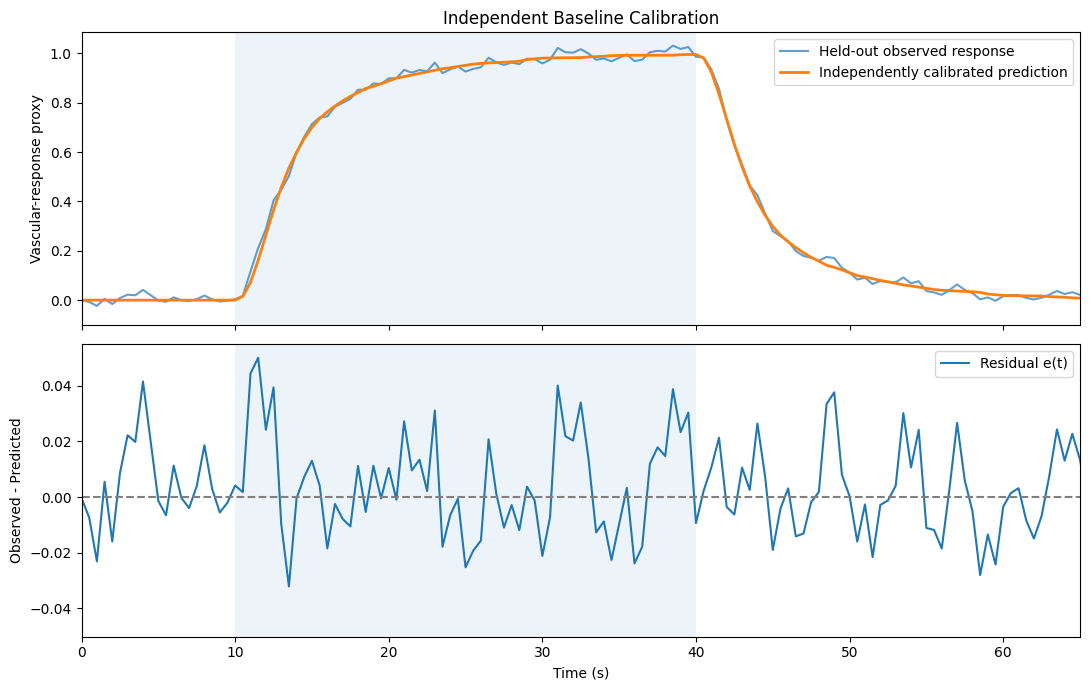


Calibration observations: 2708
FIR coefficients: 101
Kernel total gain: 0.99949

INDEPENDENT CALIBRATION COMPLETED


In [5]:
# STEP 3C — Independent neural-to-vascular calibration
# Implements the residual definition in manuscript Eq. 6.1

import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import nnls
from numpy.lib.stride_tricks import sliding_window_view

CALIBRATION_SEED = 20261018

SAMPLE_STRIDE = 5
SAMPLE_INTERVAL = DT * SAMPLE_STRIDE
KERNEL_DURATION_S = 50.0

N_LAGS = int(KERNEL_DURATION_S / SAMPLE_INTERVAL) + 1

OBS_NOISE_SD = 0.015
OBS_NOISE_RHO = 0.35

LAMBDA_SMOOTH = 0.20
LAMBDA_RIDGE = 1e-4

rng_protocol = np.random.default_rng(CALIBRATION_SEED)
rng_training = np.random.default_rng(CALIBRATION_SEED + 1)
rng_testing = np.random.default_rng(CALIBRATION_SEED + 2)


def observation_noise(rng, length):
    noise = np.empty(length)
    noise[0] = OBS_NOISE_SD * rng.standard_normal()

    innovations = rng.standard_normal(length - 1)

    for k in range(1, length):
        noise[k] = (
            OBS_NOISE_RHO * noise[k-1]
            + OBS_NOISE_SD
            * np.sqrt(1 - OBS_NOISE_RHO**2)
            * innovations[k-1]
        )

    return noise


def lag_matrix(signal):
    signal = np.asarray(signal, dtype=float)

    padded = np.pad(
        signal, (N_LAGS - 1, 0)
    )

    return sliding_window_view(
        padded, N_LAGS
    )[:, ::-1].copy()


# Independent randomized calibration stimuli
X_train = []
y_train = []

for trial in range(8):

    cursor = 10
    windows = []

    for pulse in range(4):
        duration = int(rng_protocol.integers(4, 26))

        windows.append((
            float(cursor),
            float(cursor + duration)
        ))

        cursor += duration + int(
            rng_protocol.integers(5, 23)
        )

    t_cal, u_cal = make_stimulus(windows)

    modulation = float(
        rng_protocol.uniform(-0.35, 0.35)
    )

    p_cal = NeuralParameters(q_ss=modulation)

    neural_cal, _ = neural_generator(
        t_cal, u_cal, p_cal
    )

    vascular_cal = simulate_vascular(
        t_cal, neural_cal, BASE_V
    )[3]

    sampled_neural = neural_cal[::SAMPLE_STRIDE]
    sampled_vascular = vascular_cal[::SAMPLE_STRIDE]

    observed = (
        sampled_vascular
        + observation_noise(
            rng_training, len(sampled_vascular)
        )
    )

    X_train.append(lag_matrix(sampled_neural))
    y_train.append(observed)


X = np.vstack(X_train)
y = np.concatenate(y_train)

# Smoothness-regularized nonnegative FIR estimation
D2 = np.diff(
    np.eye(N_LAGS), n=2, axis=0
)

X_augmented = np.vstack([
    X,
    np.sqrt(LAMBDA_SMOOTH) * D2,
    np.sqrt(LAMBDA_RIDGE) * np.eye(N_LAGS)
])

y_augmented = np.concatenate([
    y,
    np.zeros(D2.shape[0] + N_LAGS)
])

calibrated_kernel, _ = nnls(
    X_augmented,
    y_augmented,
    maxiter=1000
)

assert np.all(np.isfinite(calibrated_kernel))
assert np.all(calibrated_kernel >= 0)


# Independent held-out evaluation
heldout_reference = {}

for protocol_name, data in simulations.items():

    neural = data["cases"]["Reference"]["neural"]
    latent_vascular = data["cases"]["Reference"]["vascular"]

    neural_sampled = neural[::SAMPLE_STRIDE]
    vascular_sampled = latent_vascular[::SAMPLE_STRIDE]

    observed = (
        vascular_sampled
        + observation_noise(
            rng_testing, len(vascular_sampled)
        )
    )

    predicted = (
        lag_matrix(neural_sampled)
        @ calibrated_kernel
    )

    residual = observed - predicted

    rmse = np.sqrt(np.mean(residual**2))
    bias = np.mean(residual)

    heldout_reference[protocol_name] = {
        "time": data["t"][::SAMPLE_STRIDE],
        "observed": observed,
        "predicted": predicted,
        "residual": residual,
        "rmse": rmse,
        "bias": bias
    }

    print(
        f"{protocol_name:24s} | "
        f"RMSE={rmse:.5f} | "
        f"Bias={bias:+.5f}"
    )


# Inspect the independently calibrated baseline prediction
result = heldout_reference["Sustained (30 s)"]
t_plot = result["time"]

fig, axes = plt.subplots(
    2, 1, figsize=(11, 7), sharex=True
)

axes[0].plot(
    t_plot,
    result["observed"],
    label="Held-out observed response",
    alpha=0.7
)

axes[0].plot(
    t_plot,
    result["predicted"],
    label="Independently calibrated prediction",
    linewidth=2
)

axes[0].set_ylabel("Vascular-response proxy")
axes[0].set_title("Independent Baseline Calibration")
axes[0].legend()

axes[1].plot(
    t_plot,
    result["residual"],
    label="Residual e(t)"
)

axes[1].axhline(
    0, color="gray", linestyle="--"
)

axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Observed - Predicted")
axes[1].legend()

for ax in axes:
    ax.axvspan(10, 40, alpha=0.08)
    ax.set_xlim(0, 65)

plt.tight_layout()
plt.show()

print("\nCalibration observations:", len(y))
print("FIR coefficients:", len(calibrated_kernel))
print("Kernel total gain:", round(calibrated_kernel.sum(), 5))

print("\nINDEPENDENT CALIBRATION COMPLETED")


## 6. Contrast M (Eq. 6.2) and complementary contrast S (Eq. 6.4)

Prespecified windows for the 30-s stimulus beginning at 10 s: **early 15–20 s** and **late 35–40 s** (clock times). **M** is the late-minus-early residual difference, where the predictor conditions on the same scenario's neural drive. **S** is the logarithmic ratio of late and early observed-to-predicted response means; it is defined only for sufficiently positive window means. A uniform gain change can change M despite leaving the noise-free S unchanged.


MAINTENANCE CONTRAST — SUSTAINED STIMULATION
Mechanism                                  M clean     M noisy     Delta M
-------------------------------------------------------------------------------------
Reference                                 -0.00158    -0.00773     0.00000
Fast recruitment failure                  -0.01952    -0.01946    -0.01795
Delayed amplification failure             -0.07620    -0.08351    -0.07462
Neural adaptation                         -0.00199     0.00493    -0.00042
Generalized vascular limitation           -0.09415    -0.08917    -0.09257


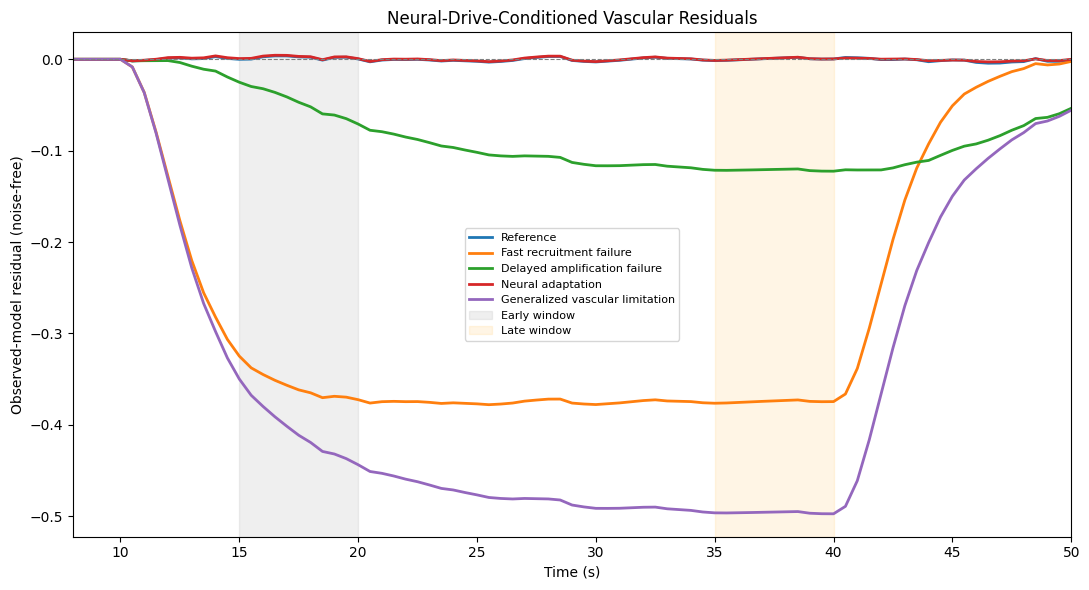


MAINTENANCE CONTRAST EVALUATION COMPLETED


In [6]:
# STEP 3D — Validation of maintenance contrast M
# Manuscript Equations 6.1 and 6.2
# Independent calibration; no refitting on test scenarios

import numpy as np
import matplotlib.pyplot as plt

DATA = simulations["Sustained (30 s)"]

t = DATA["t"][::SAMPLE_STRIDE]

early_mask = (t >= 15.0) & (t < 20.0)
late_mask = (t >= 35.0) & (t < 40.0)

assert early_mask.sum() > 0
assert late_mask.sum() > 0

SEED_M = 20261019

case_names = list(DATA["cases"].keys())

noise_seeds = np.random.SeedSequence(
    SEED_M
).spawn(len(case_names))


def maintenance_contrast(residual):
    return (
        np.mean(residual[late_mask])
        - np.mean(residual[early_mask])
    )


maintenance_results = {}

for name, seed in zip(case_names, noise_seeds):

    case = DATA["cases"][name]

    neural = case["neural"][::SAMPLE_STRIDE]
    vascular = case["vascular"][::SAMPLE_STRIDE]

    # Independently calibrated neural-to-vascular prediction
    predicted = lag_matrix(neural) @ calibrated_kernel

    # Model-implied residual without observation noise
    residual_clean = vascular - predicted

    # Independent simulated observation noise
    rng = np.random.default_rng(seed)

    observed = vascular + observation_noise(
        rng, len(vascular)
    )

    # Equation 6.1
    residual_observed = observed - predicted

    # Equation 6.2
    M_clean = maintenance_contrast(residual_clean)
    M_observed = maintenance_contrast(residual_observed)

    maintenance_results[name] = {
        "time": t,
        "neural": neural,
        "predicted": predicted,
        "observed": observed,
        "residual_clean": residual_clean,
        "residual_observed": residual_observed,
        "M_clean": M_clean,
        "M_observed": M_observed
    }


reference = maintenance_results["Reference"]

M_reference_clean = reference["M_clean"]
M_reference_observed = reference["M_observed"]


print("\nMAINTENANCE CONTRAST — SUSTAINED STIMULATION")
print("=" * 85)

print(
    f"{'Mechanism':38s}"
    f"{'M clean':>12s}"
    f"{'M noisy':>12s}"
    f"{'Delta M':>12s}"
)

print("-" * 85)

for name, result in maintenance_results.items():

    delta_M = result["M_clean"] - M_reference_clean

    print(
        f"{name:38s}"
        f"{result['M_clean']:12.5f}"
        f"{result['M_observed']:12.5f}"
        f"{delta_M:12.5f}"
    )


# Visual comparison of model-implied residuals
fig, ax = plt.subplots(figsize=(11, 6))

for name, result in maintenance_results.items():

    ax.plot(
        result["time"],
        result["residual_clean"],
        linewidth=2,
        label=name
    )

ax.axhline(
    0.0,
    color="gray",
    linestyle="--",
    linewidth=0.8
)

ax.axvspan(
    15, 20,
    color="gray",
    alpha=0.12,
    label="Early window"
)

ax.axvspan(
    35, 40,
    color="orange",
    alpha=0.10,
    label="Late window"
)

ax.set_xlim(8, 50)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Observed-model residual (noise-free)")
ax.set_title(
    "Neural-Drive-Conditioned Vascular Residuals"
)

ax.legend(
    loc="best",
    fontsize=8
)

plt.tight_layout()
plt.show()


# Numerical checks only; no imposed physiological outcome
for name, result in maintenance_results.items():

    assert np.isfinite(result["M_clean"])
    assert np.isfinite(result["M_observed"])

    assert len(result["predicted"]) == len(t)

print("\nMAINTENANCE CONTRAST EVALUATION COMPLETED")


In [7]:
# STEP 3G — Gain-normalized response-shape contrast
# Compare original Eq. 6.2 with proposed complementary S

import numpy as np

data = simulations["Sustained (30 s)"]
time = data["t"][::SAMPLE_STRIDE]

early = (time >= 15) & (time < 20)
late = (time >= 35) & (time < 40)

shape_results = {}

for name, case in data["cases"].items():

    observed = case["vascular"][::SAMPLE_STRIDE]

    neural = case["neural"][::SAMPLE_STRIDE]

    predicted = lag_matrix(neural) @ calibrated_kernel

    # Original signed residual contrast
    residual = observed - predicted

    M = (
        residual[late].mean()
        - residual[early].mean()
    )

    # Relative early and late gains
    observed_early = observed[early].mean()
    observed_late = observed[late].mean()

    predicted_early = predicted[early].mean()
    predicted_late = predicted[late].mean()

    values = [
        observed_early, observed_late,
        predicted_early, predicted_late
    ]

    if not all(np.isfinite(v) and v > 1e-8 for v in values):
        raise ValueError(
            f"Positive-response requirement failed: {name}"
        )

    gain_early = observed_early / predicted_early
    gain_late = observed_late / predicted_late

    # Proposed response-shape contrast
    S = np.log(gain_late / gain_early)

    shape_results[name] = {
        "M": M,
        "S": S,
        "gain_early": gain_early,
        "gain_late": gain_late
    }


reference_S = shape_results["Reference"]["S"]

print("\nGAIN-NORMALIZED RESPONSE ANALYSIS")
print("=" * 90)

print(
    f"{'Mechanism':37s}"
    f"{'Original M':>13s}"
    f"{'Shape S':>13s}"
    f"{'Delta S':>13s}"
)

print("-" * 90)

for name, result in shape_results.items():

    delta_S = result["S"] - reference_S

    print(
        f"{name:37s}"
        f"{result['M']:13.5f}"
        f"{result['S']:13.5f}"
        f"{delta_S:13.5f}"
    )

print("\nGAIN-SHAPE COMPARISON COMPLETED")



GAIN-NORMALIZED RESPONSE ANALYSIS
Mechanism                               Original M      Shape S      Delta S
------------------------------------------------------------------------------------------
Reference                                 -0.00158     -0.00202      0.00000
Fast recruitment failure                  -0.01952      0.10713      0.10915
Delayed amplification failure             -0.07620     -0.07278     -0.07075
Neural adaptation                         -0.00199     -0.00280     -0.00077
Generalized vascular limitation           -0.09415     -0.00202     -0.00000

GAIN-SHAPE COMPARISON COMPLETED


## 7. Duration-by-mechanism contrasts

Brief-versus-sustained duration dependence is summarized using a terminal 2-s response window. These are **model-implied descriptive interactions**, not significance-tested experimental intervention × duration effects.


MECHANISM × STIMULUS-DURATION ANALYSIS
Mechanism                             Brief effect  Long effect   Interaction  Conditioned I
------------------------------------------------------------------------------------------
Reference                                  0.00000      0.00000       0.00000        0.00000
Fast recruitment failure                  -0.47520     -0.37705       0.09816        0.09881
Delayed amplification failure             -0.02480     -0.12295      -0.09816       -0.09824
Neural adaptation                         -0.06097     -0.35828      -0.29732       -0.00081
Generalized vascular limitation           -0.50000     -0.50000      -0.00000        0.00056


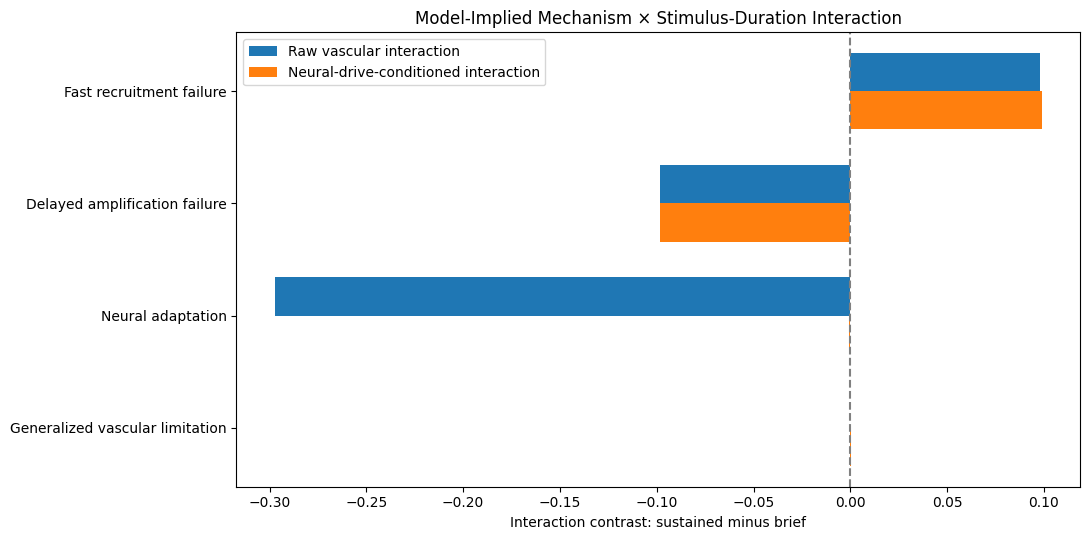


DURATION-INTERACTION ANALYSIS COMPLETED


In [8]:
# STEP 3F — Mechanism × stimulus-duration interaction
# H2: Model-implied duration dependence
# No refitting, no imposed interaction direction

import numpy as np
import matplotlib.pyplot as plt

DURATIONS = {
    "Brief": "Brief (5 s)",
    "Sustained": "Sustained (30 s)"
}

TERMINAL_WINDOW_S = 2.0

duration_results = {}

for label, protocol_name in DURATIONS.items():

    data = simulations[protocol_name]
    t = data["t"][::SAMPLE_STRIDE]

    stimulation_end = max(
        end for start, end in protocols[protocol_name]
    )

    terminal = (
        (t >= stimulation_end - TERMINAL_WINDOW_S)
        & (t < stimulation_end)
    )

    assert terminal.sum() >= 3

    ref_case = data["cases"]["Reference"]

    v_ref = ref_case["vascular"][::SAMPLE_STRIDE]
    n_ref = ref_case["neural"][::SAMPLE_STRIDE]

    predicted_ref = (
        lag_matrix(n_ref) @ calibrated_kernel
    )

    reference_response = v_ref[terminal].mean()
    reference_prediction = predicted_ref[terminal].mean()

    assert reference_response > 0
    assert reference_prediction > 0

    duration_results[label] = {}

    for mechanism, case in data["cases"].items():

        v = case["vascular"][::SAMPLE_STRIDE]
        n = case["neural"][::SAMPLE_STRIDE]

        predicted = lag_matrix(n) @ calibrated_kernel

        # Raw relative vascular difference from reference
        raw_effect = (
            v[terminal].mean() / reference_response
            - 1.0
        )

        # Neural-drive-conditioned relative residual,
        # corrected for reference calibration error
        conditioned_effect = (
            (v[terminal] - predicted[terminal]).mean()
            / predicted[terminal].mean()
            -
            (v_ref[terminal] - predicted_ref[terminal]).mean()
            / reference_prediction
        )

        duration_results[label][mechanism] = {
            "raw": raw_effect,
            "conditioned": conditioned_effect
        }


interaction_results = {}

print("\nMECHANISM × STIMULUS-DURATION ANALYSIS")
print("=" * 90)
print(
    f"{'Mechanism':37s}"
    f"{'Brief effect':>13s}"
    f"{'Long effect':>13s}"
    f"{'Interaction':>14s}"
    f"{'Conditioned I':>15s}"
)
print("-" * 90)

for mechanism in SCENARIOS:

    brief = duration_results["Brief"][mechanism]
    long = duration_results["Sustained"][mechanism]

    raw_interaction = long["raw"] - brief["raw"]

    conditioned_interaction = (
        long["conditioned"] - brief["conditioned"]
    )

    interaction_results[mechanism] = {
        "raw": raw_interaction,
        "conditioned": conditioned_interaction
    }

    print(
        f"{mechanism:37s}"
        f"{brief['raw']:13.5f}"
        f"{long['raw']:13.5f}"
        f"{raw_interaction:14.5f}"
        f"{conditioned_interaction:15.5f}"
    )


# Plot duration-interaction contrasts
names = [
    name for name in SCENARIOS
    if name != "Reference"
]

raw = np.array([
    interaction_results[name]["raw"]
    for name in names
])

conditioned = np.array([
    interaction_results[name]["conditioned"]
    for name in names
])

fig, ax = plt.subplots(figsize=(11, 5.5))

y = np.arange(len(names))
bar_h = 0.34

ax.barh(
    y - bar_h/2,
    raw,
    height=bar_h,
    label="Raw vascular interaction"
)

ax.barh(
    y + bar_h/2,
    conditioned,
    height=bar_h,
    label="Neural-drive-conditioned interaction"
)

ax.axvline(0, linestyle="--", color="gray")

ax.set_yticks(y, names)
ax.invert_yaxis()

ax.set_xlabel(
    "Interaction contrast: sustained minus brief"
)

ax.set_title(
    "Model-Implied Mechanism × Stimulus-Duration Interaction"
)

ax.legend()
plt.tight_layout()
plt.show()


# Numerical integrity checks only
all_values = np.array([
    value
    for result in interaction_results.values()
    for value in result.values()
])

assert np.all(np.isfinite(all_values))

print("\nDURATION-INTERACTION ANALYSIS COMPLETED")


## 8. Measurement-artifact and Monte Carlo diagnostics

A fixed 300-draw reference-noise comparison evaluates changes in **M**, including ±1.5-s shifts, −0.06-unit baseline drift, and 15% late neural overestimation. A separate 600-draw calibration / 300-draw evaluation examines **S**. Values of 100% flagged correspond to deliberately selected simulated perturbations, not clinical test sensitivity. Positive-window validity is reported explicitly.


MAINTENANCE ROBUSTNESS — 300 NOISE REALIZATIONS
Condition                              Clean M    Delta M   Flag rate
--------------------------------------------------------------------------------------------
Reference                             -0.00158    0.00000        5.3%
Neural adaptation                     -0.00199   -0.00042        5.3%
Fast recruitment failure              -0.01952   -0.01795       55.0%
Delayed amplification failure         -0.07620   -0.07462      100.0%
Generalized vascular limitation       -0.09415   -0.09257      100.0%
Latency +1.5 s                         0.07743    0.07901      100.0%
Latency -1.5 s                        -0.05723   -0.05565      100.0%
Downward baseline drift               -0.04158   -0.04000       99.7%
Late neural overestimation            -0.09672   -0.09514      100.0%


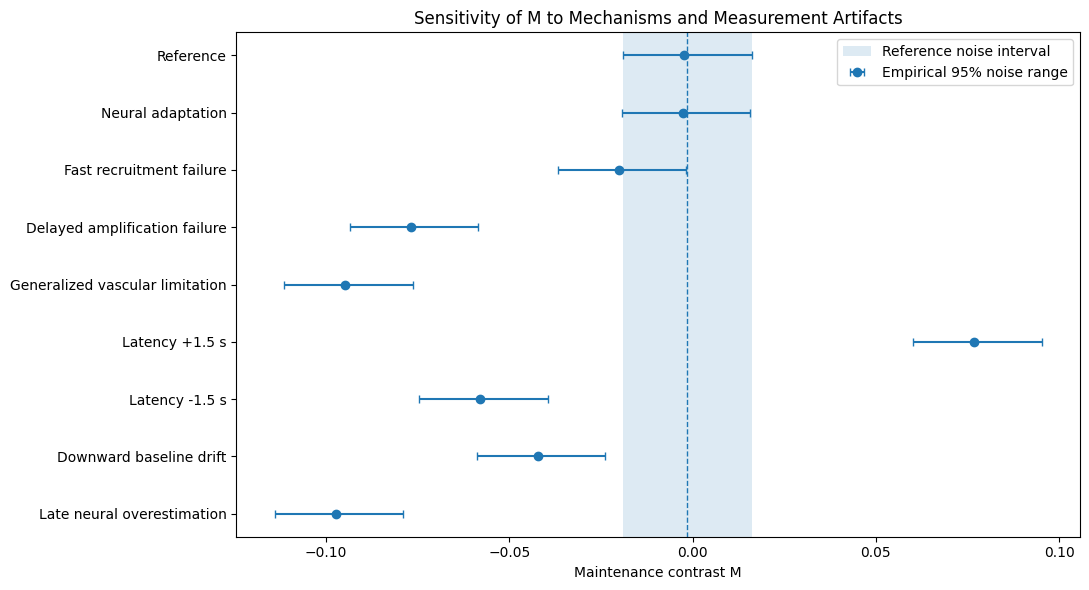


Reference noise interval: [-0.01883, 0.01622]

MAINTENANCE ROBUSTNESS COMPLETED


In [9]:
# STEP 3E — Maintenance contrast robustness
# Fixed independent calibration; no refitting

import numpy as np
import matplotlib.pyplot as plt

R = 300
ROBUSTNESS_SEED = 20261020

cases = simulations["Sustained (30 s)"]["cases"]
time = simulations["Sustained (30 s)"]["t"][::SAMPLE_STRIDE]

ref_n = cases["Reference"]["neural"][::SAMPLE_STRIDE]
ref_v = cases["Reference"]["vascular"][::SAMPLE_STRIDE]

early = (time >= 15) & (time < 20)
late = (time >= 35) & (time < 40)

# Time-dependent measurement disturbances
progress = np.clip((time - 10) / 30, 0, 1)

def shifted_signal(signal, delay):
    return np.interp(
        time - delay, time, signal,
        left=0.0, right=0.0
    )

# Each entry: (actual vascular signal, measured neural input)
test_conditions = {
    "Reference": (ref_v, ref_n),

    "Neural adaptation": (
        cases["Neural adaptation"]["vascular"][::SAMPLE_STRIDE],
        cases["Neural adaptation"]["neural"][::SAMPLE_STRIDE]
    ),

    "Fast recruitment failure": (
        cases["Fast recruitment failure"]["vascular"][::SAMPLE_STRIDE],
        ref_n
    ),

    "Delayed amplification failure": (
        cases["Delayed amplification failure"]["vascular"][::SAMPLE_STRIDE],
        ref_n
    ),

    "Generalized vascular limitation": (
        cases["Generalized vascular limitation"]["vascular"][::SAMPLE_STRIDE],
        ref_n
    ),

    "Latency +1.5 s": (
        shifted_signal(ref_v, 1.5), ref_n
    ),

    "Latency -1.5 s": (
        shifted_signal(ref_v, -1.5), ref_n
    ),

    "Downward baseline drift": (
        ref_v - 0.06 * progress, ref_n
    ),

    "Late neural overestimation": (
        ref_v, ref_n * (1 + 0.15 * progress)
    )
}


def calculate_M(signal, measured_neural):
    predicted = (
        lag_matrix(measured_neural) @ calibrated_kernel
    )

    residual = signal - predicted

    return (
        residual[late].mean()
        - residual[early].mean()
    )


# Shared noise draws enable paired comparisons.
seeds = np.random.SeedSequence(
    ROBUSTNESS_SEED
).spawn(R)

noise = np.stack([
    observation_noise(
        np.random.default_rng(s), len(time)
    )
    for s in seeds
])

noise_contrast = (
    noise[:, late].mean(axis=1)
    - noise[:, early].mean(axis=1)
)

clean_M = {
    name: calculate_M(v, n)
    for name, (v, n) in test_conditions.items()
}

# Empirical reference interval under observation noise
null_samples = (
    clean_M["Reference"] + noise_contrast
)

null_low, null_high = np.quantile(
    null_samples, [0.025, 0.975]
)

results_robust = {}

print("\nMAINTENANCE ROBUSTNESS — 300 NOISE REALIZATIONS")
print("=" * 92)

print(
    f"{'Condition':35s}"
    f"{'Clean M':>11s}"
    f"{'Delta M':>11s}"
    f"{'Flag rate':>12s}"
)
print("-" * 92)

for name, M0 in clean_M.items():

    samples = M0 + noise_contrast

    flag_rate = np.mean(
        (samples < null_low)
        | (samples > null_high)
    )

    lo, median, hi = np.quantile(
        samples, [0.025, 0.5, 0.975]
    )

    results_robust[name] = {
        "clean": M0,
        "median": median,
        "low": lo,
        "high": hi,
        "flag_rate": flag_rate
    }

    print(
        f"{name:35s}"
        f"{M0:11.5f}"
        f"{M0-clean_M['Reference']:11.5f}"
        f"{100*flag_rate:11.1f}%"
    )


# Figure: empirical noise intervals across scenarios
names = list(results_robust)
y = np.arange(len(names))

medians = np.array([
    results_robust[n]["median"] for n in names
])
lower = np.array([
    results_robust[n]["low"] for n in names
])
upper = np.array([
    results_robust[n]["high"] for n in names
])

fig, ax = plt.subplots(figsize=(11, 6))

ax.axvspan(
    null_low, null_high,
    alpha=0.15,
    label="Reference noise interval"
)

ax.errorbar(
    medians, y,
    xerr=[medians-lower, upper-medians],
    fmt="o",
    capsize=3,
    label="Empirical 95% noise range"
)

ax.set_yticks(y, names)
ax.invert_yaxis()
ax.axvline(
    clean_M["Reference"],
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("Maintenance contrast M")
ax.set_title(
    "Sensitivity of M to Mechanisms and Measurement Artifacts"
)
ax.legend()
plt.tight_layout()
plt.show()

assert all(np.isfinite(list(clean_M.values())))

print("\nReference noise interval:",
      f"[{null_low:.5f}, {null_high:.5f}]")

print("\nMAINTENANCE ROBUSTNESS COMPLETED")


In [10]:
# ============================================================
# STEP 3H — INDEPENDENT VALIDATION OF SHAPE CONTRAST S
# Manuscript: Astrovascular Response Dynamics
# Corrected reproducible version
# ============================================================

import numpy as np

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

R_CAL = 600
R_TEST = 300
SEED_S = 20261021

t_s = simulations["Sustained (30 s)"]["t"][::SAMPLE_STRIDE]

E = (t_s >= 15.0) & (t_s < 20.0)
L = (t_s >= 35.0) & (t_s < 40.0)

assert E.sum() > 0
assert L.sum() > 0
assert not np.any(E & L)

conditions = test_conditions


# ------------------------------------------------------------
# 2. Shape contrast
# ------------------------------------------------------------

def shape_samples(v, n, noise_matrix):
    """
    Gain-normalized late-versus-early response contrast.

    S = log(V_late / V_early)
        - log(Vhat_late / Vhat_early)

    Requires strictly positive window means.
    """

    v = np.asarray(v, dtype=float)
    n = np.asarray(n, dtype=float)
    noise_matrix = np.asarray(noise_matrix, dtype=float)

    assert len(v) == len(t_s)
    assert len(n) == len(t_s)
    assert noise_matrix.ndim == 2
    assert noise_matrix.shape[1] == len(t_s)

    predicted = lag_matrix(n) @ calibrated_kernel

    pe = predicted[E].mean()
    pl = predicted[L].mean()

    ve = (
        v[E].mean()
        + noise_matrix[:, E].mean(axis=1)
    )

    vl = (
        v[L].mean()
        + noise_matrix[:, L].mean(axis=1)
    )

    valid = (
        (pe > 1e-8)
        & (pl > 1e-8)
        & (ve > 1e-8)
        & (vl > 1e-8)
        & np.isfinite(ve)
        & np.isfinite(vl)
    )

    values = np.full(
        noise_matrix.shape[0],
        np.nan,
        dtype=float
    )

    if np.any(valid):
        values[valid] = (
            np.log(vl[valid] / ve[valid])
            - np.log(pl / pe)
        )

    return values


# ------------------------------------------------------------
# 3. Corrected reproducible noise generation
# ------------------------------------------------------------

def generate_noise(seed, count):
    """
    Accepts either an integer or NumPy SeedSequence.

    Reconstructing the root ensures deterministic
    results when the same experiment is rerun.
    """

    if isinstance(seed, np.random.SeedSequence):

        root = np.random.SeedSequence(
            entropy=seed.entropy,
            spawn_key=seed.spawn_key,
            pool_size=seed.pool_size
        )

    else:
        root = np.random.SeedSequence(seed)

    child_seeds = root.spawn(count)

    noise_matrix = np.stack([
        observation_noise(
            np.random.default_rng(child_seed),
            len(t_s)
        )
        for child_seed in child_seeds
    ])

    assert noise_matrix.shape == (
        count, len(t_s)
    )

    assert np.all(np.isfinite(noise_matrix))

    return noise_matrix


# ------------------------------------------------------------
# 4. Independent null calibration
# ------------------------------------------------------------

v_ref, n_ref = conditions["Reference"]

calibration_noise = generate_noise(
    SEED_S,
    R_CAL
)

null_S = shape_samples(
    v_ref,
    n_ref,
    calibration_noise
)

if not np.all(np.isfinite(null_S)):
    raise ValueError(
        "Invalid shape contrast in reference calibration."
    )

null_bounds = np.quantile(
    null_S,
    [0.025, 0.975]
)

print("\nINDEPENDENT NULL CALIBRATION")
print("=" * 65)

print("Calibration realizations:", R_CAL)

print(
    "Reference limits:",
    np.round(null_bounds, 6)
)


# ------------------------------------------------------------
# 5. Independent test realizations
# ------------------------------------------------------------

condition_seeds = np.random.SeedSequence(
    SEED_S + 1
).spawn(len(conditions))

S_robustness = {}

print("\nSHAPE-CONTRAST ROBUSTNESS")
print("=" * 90)

print(
    f"{'Condition':35s}"
    f"{'Median S':>13s}"
    f"{'Flag rate':>13s}"
    f"{'Invalid':>11s}"
)

print("-" * 90)


for (name, (v, n)), seed in zip(
    conditions.items(),
    condition_seeds
):

    draws = generate_noise(
        seed,
        R_TEST
    )

    samples = shape_samples(
        v,
        n,
        draws
    )

    valid = np.isfinite(samples)

    invalid_rate = np.mean(~valid)

    if valid.any():

        valid_samples = samples[valid]

        flagged = (
            (valid_samples < null_bounds[0])
            | (valid_samples > null_bounds[1])
        )

        flag_rate = np.mean(flagged)

        median = np.median(valid_samples)

        lower, upper = np.quantile(
            valid_samples,
            [0.025, 0.975]
        )

    else:

        flag_rate = np.nan
        median = np.nan
        lower = np.nan
        upper = np.nan

    S_robustness[name] = {
        "median": median,
        "low": lower,
        "high": upper,
        "flag_rate": flag_rate,
        "invalid_rate": invalid_rate,
        "valid_count": int(valid.sum())
    }

    print(
        f"{name:35s}"
        f"{median:13.5f}"
        f"{100 * flag_rate:12.1f}%"
        f"{100 * invalid_rate:10.1f}%"
    )


# ------------------------------------------------------------
# 6. Numerical and reproducibility checks
# ------------------------------------------------------------

assert len(S_robustness) == len(conditions)

assert np.all(np.isfinite(null_bounds))

assert null_bounds[0] < null_bounds[1]

# Same seed must reproduce identical noise
repro_test_1 = generate_noise(12345, 3)
repro_test_2 = generate_noise(12345, 3)

np.testing.assert_array_equal(
    repro_test_1,
    repro_test_2
)

print("\n" + "=" * 65)
print("INDEPENDENT SHAPE VALIDATION COMPLETED")
print("Reproducibility check: PASSED")
print("=" * 65)



INDEPENDENT NULL CALIBRATION
Calibration realizations: 600
Reference limits: [-0.023762  0.018864]

SHAPE-CONTRAST ROBUSTNESS
Condition                               Median S    Flag rate    Invalid
------------------------------------------------------------------------------------------


Reference                               -0.00324         4.0%       0.0%
Neural adaptation                       -0.00426        13.3%       0.0%
Fast recruitment failure                 0.11025       100.0%       0.0%


Delayed amplification failure           -0.07257       100.0%       0.0%


Generalized vascular limitation         -0.00432        33.3%       0.0%
Latency +1.5 s                           0.10302       100.0%       0.0%
Latency -1.5 s                          -0.06732       100.0%       0.0%
Downward baseline drift                 -0.03991        94.3%       0.0%


Late neural overestimation              -0.08698       100.0%       0.0%

INDEPENDENT SHAPE VALIDATION COMPLETED
Reproducibility check: PASSED


## 9. Amplitude-matched calibration and uncertainty

This diagnostic checks why the flag rate of **S** rises under fixed additive noise and reduced vascular amplitude. Full-gain and half-gain independent null samples each contain 800 calibration draws; their corresponding evaluation samples contain 500 independent draws. **Amplitude-matched thresholds presume the simulated gain is known**; in actual data, gain must be estimated without using the ground-truth mechanism.

In [11]:
# ============================================================
# STEP 3I — AMPLITUDE-MATCHED NOISE CALIBRATION
# Astrovascular Response Dynamics
#
# Corrected numerical tolerance
# Independent calibration and test samples
# Deterministic random streams
# No parameter fitting or outcome-dependent thresholds
# ============================================================

import numpy as np

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

ROOT_SEED = 20261022

N_CAL = 800
N_TEST = 500

NOISE_SD = 0.015
NOISE_RHO = 0.35

assert N_CAL > 100
assert N_TEST > 100
assert NOISE_SD > 0
assert abs(NOISE_RHO) < 1

time = simulations["Sustained (30 s)"]["t"][
    ::SAMPLE_STRIDE
]

early = (time >= 15.0) & (time < 20.0)
late = (time >= 35.0) & (time < 40.0)

assert early.sum() > 0
assert late.sum() > 0


# ------------------------------------------------------------
# 2. Retrieve independently simulated vascular responses
# ------------------------------------------------------------

v_full, n_full = test_conditions["Reference"]

v_half, n_half = test_conditions[
    "Generalized vascular limitation"
]

v_full = np.asarray(v_full, dtype=float)
v_half = np.asarray(v_half, dtype=float)

n_full = np.asarray(n_full, dtype=float)
n_half = np.asarray(n_half, dtype=float)

assert all(
    len(x) == len(time)
    for x in (v_full, v_half, n_full, n_half)
)

assert all(
    np.all(np.isfinite(x))
    for x in (v_full, v_half, n_full, n_half)
)


# ------------------------------------------------------------
# 3. Numerical verification of the gain-only perturbation
# ------------------------------------------------------------

expected_half = 0.5 * v_full

maximum_difference = np.max(
    np.abs(v_half - expected_half)
)

# The two responses were integrated independently using
# an adaptive numerical ODE solver.
# Machine-precision identity is not expected.

np.testing.assert_allclose(
    v_half,
    expected_half,
    rtol=2e-6,
    atol=5e-7
)

# Neural drive must remain unchanged in a gain-only case.

np.testing.assert_allclose(
    n_half,
    n_full,
    rtol=0,
    atol=1e-10
)

estimated_gain = (
    np.dot(v_full, v_half)
    / np.dot(v_full, v_full)
)

print("\nGAIN-ONLY PERTURBATION CHECK")
print("=" * 65)

print(
    "Maximum numerical difference:",
    f"{maximum_difference:.3e}"
)

print(
    "Estimated vascular scaling:",
    f"{estimated_gain:.8f}"
)

print("Numerical consistency: PASSED")


# ------------------------------------------------------------
# 4. Deterministic independent AR(1) noise generator
# ------------------------------------------------------------

def generate_ar1_matrix(seed, n_draws, n_time):

    rng = np.random.default_rng(seed)

    innovations = rng.standard_normal(
        (n_draws, n_time)
    )

    noise = np.empty_like(innovations)

    noise[:, 0] = (
        NOISE_SD * innovations[:, 0]
    )

    innovation_scale = (
        NOISE_SD * np.sqrt(1 - NOISE_RHO**2)
    )

    for j in range(1, n_time):

        noise[:, j] = (
            NOISE_RHO * noise[:, j-1]
            + innovation_scale * innovations[:, j]
        )

    return noise


# ------------------------------------------------------------
# 5. Gain-normalized shape contrast S
# ------------------------------------------------------------

def compute_shape_samples(
    vascular,
    neural,
    noise_matrix
):
    """
    S = log(V_late / V_early)
        - log(Vhat_late / Vhat_early)

    The predictor is independently calibrated and fixed.
    """

    predicted = (
        lag_matrix(neural) @ calibrated_kernel
    )

    pred_early = np.mean(predicted[early])
    pred_late = np.mean(predicted[late])

    observed_early = (
        np.mean(vascular[early])
        + np.mean(noise_matrix[:, early], axis=1)
    )

    observed_late = (
        np.mean(vascular[late])
        + np.mean(noise_matrix[:, late], axis=1)
    )

    valid = (
        (pred_early > 1e-8)
        & (pred_late > 1e-8)
        & (observed_early > 1e-8)
        & (observed_late > 1e-8)
        & np.isfinite(observed_early)
        & np.isfinite(observed_late)
    )

    result = np.full(
        noise_matrix.shape[0],
        np.nan
    )

    result[valid] = (
        np.log(
            observed_late[valid]
            / observed_early[valid]
        )
        - np.log(pred_late / pred_early)
    )

    return result


# ------------------------------------------------------------
# 6. Four independent random streams
# ------------------------------------------------------------

seeds = np.random.SeedSequence(
    ROOT_SEED
).spawn(4)

noise_cal_full = generate_ar1_matrix(
    seeds[0], N_CAL, len(time)
)

noise_cal_half = generate_ar1_matrix(
    seeds[1], N_CAL, len(time)
)

noise_test_full = generate_ar1_matrix(
    seeds[2], N_TEST, len(time)
)

noise_test_half = generate_ar1_matrix(
    seeds[3], N_TEST, len(time)
)


# ------------------------------------------------------------
# 7. Independent null calibration
# ------------------------------------------------------------

null_full = compute_shape_samples(
    v_full, n_full, noise_cal_full
)

null_half = compute_shape_samples(
    v_half, n_half, noise_cal_half
)

valid_null_full = null_full[np.isfinite(null_full)]
valid_null_half = null_half[np.isfinite(null_half)]

if len(valid_null_full) < 0.9 * N_CAL:
    raise RuntimeError(
        "Too many invalid full-gain calibration samples."
    )

if len(valid_null_half) < 0.9 * N_CAL:
    raise RuntimeError(
        "Too many invalid half-gain calibration samples."
    )

bounds_full = np.quantile(
    valid_null_full,
    [0.025, 0.975]
)

bounds_half = np.quantile(
    valid_null_half,
    [0.025, 0.975]
)


# ------------------------------------------------------------
# 8. Independent test evaluation
# ------------------------------------------------------------

test_full = compute_shape_samples(
    v_full, n_full, noise_test_full
)

test_half = compute_shape_samples(
    v_half, n_half, noise_test_half
)

valid_test_full = test_full[np.isfinite(test_full)]
valid_test_half = test_half[np.isfinite(test_half)]


def calculate_flag_rate(samples, bounds):

    valid = samples[np.isfinite(samples)]

    if len(valid) == 0:
        return np.nan

    flagged = (
        (valid < bounds[0])
        | (valid > bounds[1])
    )

    return 100.0 * np.mean(flagged)


full_matched = calculate_flag_rate(
    test_full, bounds_full
)

half_unmatched = calculate_flag_rate(
    test_half, bounds_full
)

half_matched = calculate_flag_rate(
    test_half, bounds_half
)


# ------------------------------------------------------------
# 9. Statistical summary
# ------------------------------------------------------------

print("\nAMPLITUDE-MATCHED NULL CALIBRATION")
print("=" * 70)

print(
    "Full-gain reference interval:",
    np.round(bounds_full, 6)
)

print(
    "Half-gain reference interval:",
    np.round(bounds_half, 6)
)

print("\nINDEPENDENT TEST RESULTS")
print("-" * 70)

print(
    "Full gain | matched calibration:   ",
    f"{full_matched:.1f}%"
)

print(
    "Half gain | unmatched calibration: ",
    f"{half_unmatched:.1f}%"
)

print(
    "Half gain | matched calibration:   ",
    f"{half_matched:.1f}%"
)


print("\nSHAPE-CONTRAST DISPERSION")
print("-" * 70)

print(
    "Full-gain SD:",
    f"{np.std(valid_test_full, ddof=1):.6f}"
)

print(
    "Half-gain SD:",
    f"{np.std(valid_test_half, ddof=1):.6f}"
)

print(
    "Full-gain median:",
    f"{np.median(valid_test_full):+.6f}"
)

print(
    "Half-gain median:",
    f"{np.median(valid_test_half):+.6f}"
)

print(
    "Difference between medians:",
    f"{np.median(valid_test_half)-np.median(valid_test_full):+.6f}"
)

print("\nVALID SAMPLE COUNTS")
print("-" * 70)

print(
    f"Full gain: {len(valid_test_full)}/{N_TEST}"
)

print(
    f"Half gain: {len(valid_test_half)}/{N_TEST}"
)


# ------------------------------------------------------------
# 10. Reproducibility and integrity checks
# ------------------------------------------------------------

noise_check_1 = generate_ar1_matrix(
    123456, 5, len(time)
)

noise_check_2 = generate_ar1_matrix(
    123456, 5, len(time)
)

np.testing.assert_array_equal(
    noise_check_1,
    noise_check_2
)

assert np.all(np.isfinite(bounds_full))
assert np.all(np.isfinite(bounds_half))

assert bounds_full[0] < bounds_full[1]
assert bounds_half[0] < bounds_half[1]

assert np.isfinite(full_matched)
assert np.isfinite(half_matched)
assert np.isfinite(half_unmatched)

print("\n" + "=" * 70)
print("AMPLITUDE-MATCHED CALIBRATION COMPLETED")
print("Numerical verification: PASSED")
print("Random-seed reproducibility: PASSED")
print("=" * 70)



GAIN-ONLY PERTURBATION CHECK
Maximum numerical difference: 4.077e-08
Estimated vascular scaling: 0.50000000
Numerical consistency: PASSED

AMPLITUDE-MATCHED NULL CALIBRATION
Full-gain reference interval: [-0.022691  0.017269]
Half-gain reference interval: [-0.042938  0.039969]

INDEPENDENT TEST RESULTS
----------------------------------------------------------------------
Full gain | matched calibration:    6.0%
Half gain | unmatched calibration:  34.8%
Half gain | matched calibration:    6.4%

SHAPE-CONTRAST DISPERSION
----------------------------------------------------------------------
Full-gain SD: 0.010843
Half-gain SD: 0.021506
Full-gain median: -0.002328
Half-gain median: -0.001087
Difference between medians: +0.001241

VALID SAMPLE COUNTS
----------------------------------------------------------------------
Full gain: 500/500
Half gain: 500/500

AMPLITUDE-MATCHED CALIBRATION COMPLETED
Numerical verification: PASSED
Random-seed reproducibility: PASSED


## 10. Publication figures, exact tabular outputs, and reproducibility manifest

Exports are derived from computed arrays—not redrawn schematics. PNG (300 dpi) and SVG figures are saved to `figures/`. CSV summaries and JSON configuration are saved to `results/`. Some analyses in the original development archive (parameter identifiability pilot, profile likelihood) are intentionally excluded from this compact core notebook; they remain exploratory and are not needed to reproduce Supplementary Tables S2–S4.

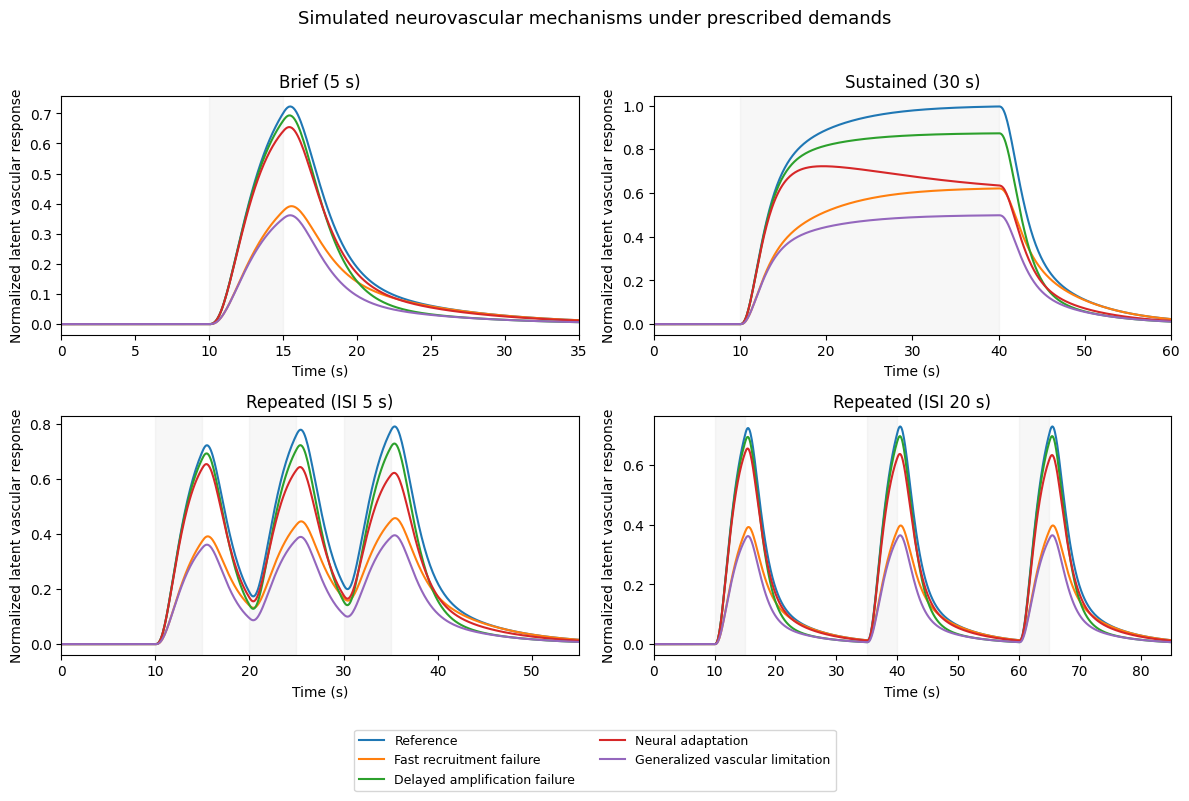

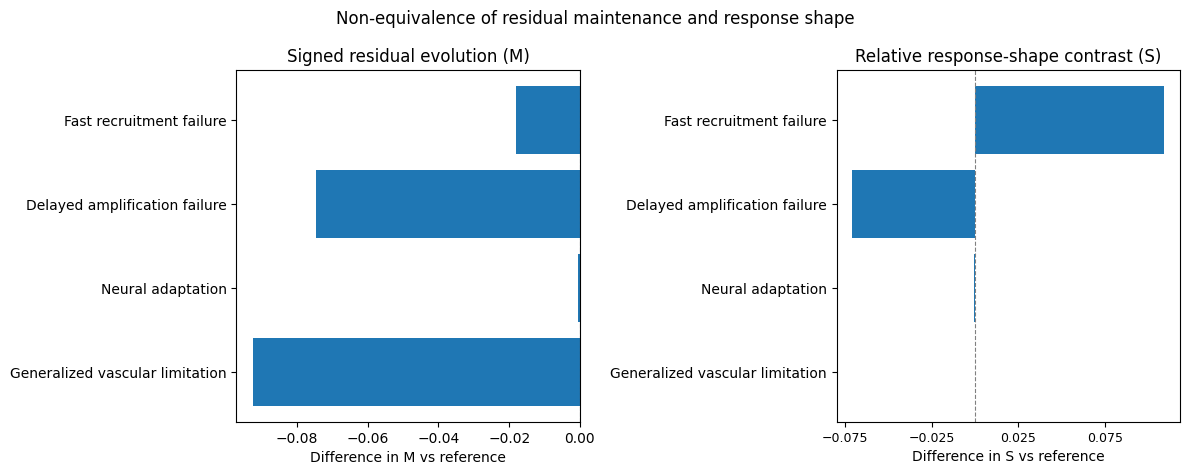


Exported tables S2–S4, two figures (PNG/SVG), and reproducibility manifest
M/S reference: -0.0015760069824380719 -0.002023775973941902
Calibration RMSE sustained: 0.016409465935216132
Full/half gain flag rates (matched): 6.0 6.4


In [12]:
# Save core tables without refitting or overwriting derived values.
fig_dir = OUTPUT / "figures"
res_dir = OUTPUT / "results"

summary = []
for name in SCENARIOS:
    record = maintenance_results[name]
    ss = shape_results[name]
    early_v = simulations["Sustained (30 s)"]["cases"][name]["vascular"]
    t_full = simulations["Sustained (30 s)"]["t"]
    ewin = (t_full >= 15) & (t_full < 20)
    lwin = (t_full >= 35) & (t_full < 40)
    summary.append({
        "mechanism": name,
        "vascular_early": float(early_v[ewin].mean()),
        "vascular_late": float(early_v[lwin].mean()),
        "M_clean": float(record["M_clean"]),
        "delta_S_vs_reference": float(ss["S"] - shape_results["Reference"]["S"]),
    })
table_s2 = pd.DataFrame(summary)
table_s2.to_csv(res_dir / "table_S2_mechanistic_contrasts.csv", index=False, float_format="%.8f")

table_s3 = pd.DataFrame([
    {"mechanism": mechanism,
     "raw_duration_interaction": float(d["raw"]),
     "conditioned_duration_interaction": float(d["conditioned"])}
    for mechanism, d in interaction_results.items() if mechanism != "Reference"
])
table_s3.to_csv(res_dir / "table_S3_duration_interactions.csv", index=False, float_format="%.8f")

table_s4 = pd.DataFrame([
    {"condition": cond, "median_S": float(d["median"]),
     "flag_rate_percent": 100 * float(d["flag_rate"]),
     "invalid_percent": 100 * float(d["invalid_rate"])}
    for cond, d in S_robustness.items()
])
table_s4.to_csv(res_dir / "table_S4_shape_sensitivity.csv", index=False, float_format="%.8f")

# Two concise final figures, corresponding to the core claims.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (protocol_name, dat) in zip(axes.flat, simulations.items()):
    for mechanism, vals in dat["cases"].items():
        ax.plot(dat["t"], vals["vascular"], lw=1.5, label=mechanism)
    for start, stop in protocols[protocol_name]:
        ax.axvspan(start, stop, alpha=0.06, color="gray")
    ax.set_xlim(0, max(stop for start, stop in protocols[protocol_name]) + 20)
    ax.set_title(protocol_name)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Normalized latent vascular response")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.005), ncol=2, fontsize=9)
fig.suptitle("Simulated neurovascular mechanisms under prescribed demands", fontsize=13)
fig.tight_layout(rect=[0, 0.10, 1, 0.96])
fig.savefig(fig_dir / "Figure_S1_mechanism_trajectories.png", dpi=300, bbox_inches="tight")
fig.savefig(fig_dir / "Figure_S1_mechanism_trajectories.svg", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
labels = [k for k in SCENARIOS if k != "Reference"]
y = np.arange(len(labels))
axes[0].barh(y, [maintenance_results[k]["M_clean"] - maintenance_results["Reference"]["M_clean"] for k in labels])
axes[1].barh(y, [shape_results[k]["S"] - shape_results["Reference"]["S"] for k in labels])
for ax in axes:
    ax.axvline(0, color="gray", lw=0.8, ls="--")
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
axes[0].set_xlabel("Difference in M vs reference")
axes[1].set_xlabel("Difference in S vs reference")
axes[0].set_title("Signed residual evolution (M)")
axes[1].set_title("Relative response-shape contrast (S)")
axes[1].set_xticks([-0.075, -0.025, 0.025, 0.075])
axes[1].tick_params(axis="x", labelsize=9)
fig.suptitle("Non-equivalence of residual maintenance and response shape", fontsize=12)
fig.tight_layout()
fig.savefig(fig_dir / "Figure_S2_M_vs_S.png", dpi=300, bbox_inches="tight")
fig.savefig(fig_dir / "Figure_S2_M_vs_S.svg", bbox_inches="tight")
plt.show()

import scipy, matplotlib, sys
manifest = {
    "purpose": "Supplementary matched-model computational feasibility (not empirical AD evidence)",
    "python": sys.version.split()[0], "numpy": np.__version__,
    "scipy": scipy.__version__, "matplotlib": matplotlib.__version__,
    "pandas": pd.__version__, "dt_seconds": DT,
    "sample_stride": SAMPLE_STRIDE, "baseline_seconds": BASELINE_S,
    "recovery_seconds": RECOVERY_S, "fir_lags": N_LAGS,
    "fir_smoothness": LAMBDA_SMOOTH, "fir_ridge": LAMBDA_RIDGE,
    "noise_sd": OBS_NOISE_SD, "noise_ar1_rho": OBS_NOISE_RHO,
    "model_reference_neural": vars(BASE_N),
    "model_reference_vascular": vars(BASE_V),
    "simulation_seeds": {"protocols": SEED, "FIR": CALIBRATION_SEED,
       "M_test": SEED_M, "M_robustness": ROBUSTNESS_SEED,
       "S_robustness": SEED_S, "amplitude_calibration": ROOT_SEED},
    "numerical_caveat": "No physiological parameter calibration or clinical validation performed"
}
(res_dir / "run_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("\nExported tables S2–S4, two figures (PNG/SVG), and reproducibility manifest")
print("M/S reference:", maintenance_results["Reference"]["M_clean"], shape_results["Reference"]["S"])
print("Calibration RMSE sustained:", heldout_reference["Sustained (30 s)"]["rmse"])
print("Full/half gain flag rates (matched):", full_matched, half_matched)
